In [ ]:
%pip -q install "setuptools<81" ftfy regex tqdm scikit-learn scikit-image pandas seaborn matplotlib pillow git+https://github.com/openai/CLIP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, sys, json, time, random, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, torchvision, clip
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR100

SEED=42
QUICK=False
RUN_TEST=False
RUN_ABLATIONS=True
RUN_CLASSICAL_BASELINE=False
RUN_STATISTICAL_ANALYSIS=True
SEEDS=[42]
BATCH_SIZE=256
EPOCHS=100 if not QUICK else 5
PATIENCE=15 if not QUICK else 3
TRAIN_SIZES=[100, 500, 2000, 10000, 40000] if not QUICK else [100, 500]
C_GRID=[0.01, 0.1, 0.316, 1.0, 10.0, 30.0, 100.0] if not QUICK else [0.316]
LR_GRID=[3e-3]  # AdamW một learning rate; theo dõi hội tụ tối đa 100 epoch
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE=='cuda', 'Hãy bật GPU trong Colab: Runtime > Change runtime type > T4 GPU'
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT=Path('/content/drive/MyDrive/CLIP_Final_Experiments') / ('QUICK_CHECK' if QUICK else 'FULL_EXPERIMENT_FINAL')
except Exception as exc:
    print('Drive chưa mount:',exc)
    OUT=Path('/content/clip_final_outputs') / ('QUICK_CHECK' if QUICK else 'FULL_EXPERIMENT_FINAL')
for name in ['data','features','tables','figures','models','logs','predictions']:(OUT/name).mkdir(parents=True,exist_ok=True)
print('Output:',OUT,'GPU:',torch.cuda.get_device_name(0),'torch:',torch.__version__,'QUICK:',QUICK,'RUN_TEST:',RUN_TEST)
if QUICK: print('CHẾ ĐỘ CHẠY THỬ: không dùng số liệu này làm kết quả cuối kỳ.')
if not QUICK and RUN_TEST: print('CẢNH BÁO: Test chỉ được chạy sau khi đã chốt cấu hình từ Validation.')
(OUT/'logs'/'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,'torchvision':torchvision.__version__,'device':torch.cuda.get_device_name(0),'seed':SEED,'quick':QUICK,'run_test':RUN_TEST,'seeds':SEEDS,'date_utc':pd.Timestamp.utcnow().isoformat(), 'experiment_version':'final_clean_v2'},indent=2))

Mounted at /content/drive
Output: /content/drive/MyDrive/CLIP_Final_Experiments/FULL_EXPERIMENT_FINAL GPU: Tesla T4 torch: 2.14.1+cu130 QUICK: False RUN_TEST: False


322

## 1. Dữ liệu, nhãn và chia tập không rò rỉ
CIFAR-100 có 50.000 ảnh train, 10.000 ảnh test và 100 fine labels (mỗi lớp test 100 ảnh). Chia stratified **40.000 train / 10.000 validation** từ tập train gốc. Test giữ nguyên, không dùng để lựa chọn mô hình. Dùng `coarse_targets` (20 superclass) để đánh giá theo nhóm.

In [ ]:
ROOT=str(OUT/'data')
raw_train=CIFAR100(ROOT,train=True,download=True)
raw_test=CIFAR100(ROOT,train=False,download=True)
labels=np.asarray(raw_train.targets,dtype=np.int64)
train_idx,val_idx=train_test_split(np.arange(len(labels)),test_size=.2,stratify=labels,random_state=SEED)
if QUICK:

    def strat_sample(indices,y,per_class):
        rng=np.random.default_rng(SEED)
        return np.sort(np.concatenate([rng.choice(indices[y[indices]==c],min(per_class,np.sum(y[indices]==c)),replace=False) for c in range(100)]))
    train_idx=strat_sample(train_idx,labels,20)
    val_idx=strat_sample(val_idx,labels,10)
    test_idx=strat_sample(np.arange(len(raw_test)),np.asarray(raw_test.targets),10)
else: test_idx=np.arange(len(raw_test))
assert not set(train_idx)&set(val_idx)
classes=raw_train.classes
print('train / val / test:',len(train_idx),len(val_idx),len(test_idx))
assert len(classes)==100
pd.DataFrame({'index':np.r_[train_idx,val_idx],'split':['train']*len(train_idx)+['val']*len(val_idx),'label':labels[np.r_[train_idx,val_idx]]}).to_csv(OUT/'tables'/'splits.csv',index=False)
(OUT/'logs'/'split_config.json').write_text(json.dumps({'train_size':len(train_idx),'val_size':len(val_idx),'test_size':len(test_idx),'seed':SEED,'quick':QUICK},indent=2))

100%|██████████| 169M/169M [38:49<00:00, 72.6kB/s]


train / val / test: 40000 10000 10000


100

## 2. Nạp CLIP pretrained và trích xuất embedding có cache
Bám theo paper: image encoder và text encoder được chiếu vào không gian chung; similarity là cosine giữa các embedding chuẩn hóa. Dùng **ViT-B/32** và preprocess chính thức từ `openai/CLIP`. Embedding được cache để không phải mã hóa ảnh lại mỗi lần thử.

In [ ]:
model,preprocess=clip.load('ViT-B/32',device=DEVICE,jit=False)
model.eval()
for p in model.parameters():p.requires_grad_(False)
print('Embedding dim:',model.visual.output_dim)
train_ds=CIFAR100(ROOT,train=True,download=False,transform=preprocess)
test_ds=CIFAR100(ROOT,train=False,download=False,transform=preprocess)

def extract_cached(dataset,idx,name):
    path=OUT/'features'/f'{name}_{"quick" if QUICK else "full"}.npz'
    if path.exists():
        z=np.load(path); assert np.array_equal(z['indices'],idx),f'Cache {name} khác split';return z['features'].astype('float32'),z['labels'].astype('int64')
    loader=DataLoader(Subset(dataset,idx.tolist()),batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=True)
    feats=[]; ys=[]
    with torch.inference_mode():
        for x,y in tqdm(loader,desc='CLIP encode '+name):
            v=model.encode_image(x.to(DEVICE,non_blocking=True)).float()
            v=torch.nn.functional.normalize(v,dim=-1)
            feats.append(v.cpu().numpy());ys.append(y.numpy())
    X=np.concatenate(feats);y=np.concatenate(ys)
    np.savez_compressed(path,features=X.astype('float16'),labels=y,indices=idx)
    return X,y
Xtr,ytr=extract_cached(train_ds,train_idx,'train')
Xva,yva=extract_cached(train_ds,val_idx,'val')
Xte,yte=extract_cached(test_ds,test_idx,'test') if RUN_TEST else (None,None)
assert Xtr.shape[1]==Xva.shape[1]==512
if RUN_TEST: assert Xte.shape[1]==512
assert np.isfinite(Xtr).all()
print('Embedding shapes:',Xtr.shape,Xva.shape, Xte.shape if RUN_TEST else 'TEST NOT LOADED')

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 210MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Embedding dim: 512


CLIP encode train:   0%|          | 0/157 [00:00<?, ?it/s]

CLIP encode val:   0%|          | 0/40 [00:00<?, ?it/s]

Embedding shapes: (40000, 512) (10000, 512) TEST NOT LOADED


## 3. Hàm đo lường thống nhất
Top-1, Top-5, Macro-F1, Weighted-F1; các nhóm dùng coarse labels CIFAR-100; lưu dự đoán để kiểm chứng. **Top-5** đo xem nhãn thật có nằm trong 5 lớp có điểm cao nhất hay không.

In [ ]:
def metrics(y,scores):
    scores=np.asarray(scores); y=np.asarray(y)
    pred=scores.argmax(axis=1)
    top5=np.argpartition(scores,-5,axis=1)[:,-5:]
    return {'n':len(y),'top1':100*accuracy_score(y,pred),'top5':100*np.mean((top5==y[:,None]).any(axis=1)),
            'macro_f1':100*f1_score(y,pred,average='macro',zero_division=0),
            'weighted_f1':100*f1_score(y,pred,average='weighted',zero_division=0)}

def save_preds(name,split,y,scores,indices):
    pred=scores.argmax(1);top5=np.argsort(-scores,axis=1)[:,:5]
    df=pd.DataFrame({'dataset_index':indices,'true':y,'pred':pred,'correct':(y==pred).astype(int),'top5_hit':(top5==y[:,None]).any(1).astype(int),
                     'true_name':[classes[i] for i in y],'pred_name':[classes[i] for i in pred],
                     'top5_classes':[';'.join(map(str,row)) for row in top5]})
    safe=name.replace(' ','_').replace('/','_')
    df.to_csv(OUT/'predictions'/f'{safe}_{split}.csv',index=False)
    return df
records=[]
def record(name,split,y,scores,indices,extra=None):
    r={'method':name,'split':split,**metrics(y,scores),**(extra or {})}
    records.append(r);save_preds(name,split,y,scores,indices)
    print(r);return r

def text_weights(template_list):
    out=[]
    with torch.inference_mode():
        for template in template_list:
            texts=[template.format(c.replace('_',' ')) for c in classes]
            tok=clip.tokenize(texts,truncate=True).to(DEVICE)
            t=model.encode_text(tok).float()
            out.append(torch.nn.functional.normalize(t,dim=-1))
        w=torch.stack(out).mean(0)
        w=torch.nn.functional.normalize(w,dim=-1)
    return w.cpu().numpy()

def evaluate_scores(name,sv,st=None):
    record(name,'val',yva,sv,val_idx)
    if RUN_TEST and st is not None:record(name,'test',yte,st,test_idx)
    return sv

## 4. Zero-shot: 0 prompt, 1 prompt và 18 prompt
Đối chứng giữ nguyên encoder và chỉ thay cách diễn đạt text. Tính embedding trung bình của 18 template rồi chuẩn hóa. Các template lấy từ notebook nhóm; **ensemble 18 là lựa chọn thực nghiệm của nhóm**, không đồng nhất với toàn bộ prompt ensemble trong paper.

In [ ]:
PROMPTS={
 'no_prompt':['{}'],
 'one_prompt':['a photo of a {}.'],
 'ensemble_18':[
 'a photo of a {}.','a blurry photo of a {}.','a black and white photo of a {}.',
 'a low contrast photo of a {}.','a high contrast photo of a {}.',
 'a bad photo of a {}.','a good photo of a {}.',
 'a photo of a small {}.','a photo of a big {}.',
 'a photo of the {}.','a blurry photo of the {}.',
 'a black and white photo of the {}.','a low contrast photo of the {}.',
 'a high contrast photo of the {}.','a bad photo of the {}.',
 'a good photo of the {}.','a photo of the small {}.','a photo of the big {}.'
 ]}
assert len(PROMPTS['ensemble_18'])==18
zero_scores={}
for name,templates in PROMPTS.items():
    w=text_weights(templates)
    zero_scores[name]={'val':Xva@w.T}
    evaluate_scores('zero_'+name,zero_scores[name]['val'],zero_scores[name].get('test'))
best_prompt=max(PROMPTS,key=lambda k:metrics(yva,zero_scores[k]['val'])['top1'])
print('Best prompt by VAL:',best_prompt)

{'method': 'zero_no_prompt', 'split': 'val', 'n': 10000, 'top1': 60.24, 'top5': np.float64(85.37), 'macro_f1': 59.09111248685339, 'weighted_f1': 59.091112486853405}
{'method': 'zero_one_prompt', 'split': 'val', 'n': 10000, 'top1': 64.38000000000001, 'top5': np.float64(88.05), 'macro_f1': 63.54348772237848, 'weighted_f1': 63.5434877223785}
{'method': 'zero_ensemble_18', 'split': 'val', 'n': 10000, 'top1': 65.33, 'top5': np.float64(89.25999999999999), 'macro_f1': 64.6569308320472, 'weighted_f1': 64.6569308320472}
Best prompt by VAL: ensemble_18


### Chọn tham số C của Logistic Regression
Thử C = 0,01; 0,1; 0,316; 1; 10; 30; 100. **Chỉ dùng Validation để chọn C**. Nếu C tốt nhất vẫn ở biên 100, ghi nhận đây là giới hạn lưới tìm kiếm, không dùng Test để điều chỉnh.


## 5. Đối chứng Dummy và linear probe (Logistic Regression)
Dummy là mốc nền. Logistic Regression huấn luyện trên **train embedding**, chọn hệ số C trên **validation**, sau đó **giữ nguyên bộ phân loại đã huấn luyện trên Train (40.000 ảnh)** để đánh giá Test. Không huấn luyện lại trên Train + Validation. Tập Test không được dùng để chọn C hay điều chỉnh mô hình.

In [ ]:
dummy=DummyClassifier(strategy='most_frequent').fit(Xtr,ytr)
dummy_va=dummy.predict_proba(Xva)
record('dummy_majority','val',yva,dummy_va,val_idx)

lr_search=[];best=None;best_val=-1
for C in C_GRID:
    t0=time.time()
    clf=LogisticRegression(C=C,max_iter=1500,solver='lbfgs')
    clf.fit(Xtr,ytr)
    sv=clf.predict_proba(Xva)
    m=record(f'lr_C_{C}','val',yva,sv,val_idx,{'C':C,'fit_seconds':round(time.time()-t0,2)})
    lr_search.append(m)
    if m['top1']>best_val:best_val=m['top1'];best=(C,clf)
pd.DataFrame(lr_search).to_csv(OUT/'tables'/'lr_validation_search.csv',index=False)
best_C,best_clf=best
print('Best C chosen ONLY on validation:',best_C)

# Chỉ lưu mô hình đã chọn trên Validation, chưa truy cập Test.
import joblib
joblib.dump(best_clf, OUT/'models'/'logistic_train_only_selected.joblib')
print('Đã lưu Logistic Regression (train-only), C =', best_C)


{'method': 'dummy_majority', 'split': 'val', 'n': 10000, 'top1': 1.0, 'top5': np.float64(5.0), 'macro_f1': 0.019801980198019802, 'weighted_f1': 0.019801980198019802}
{'method': 'lr_C_0.01', 'split': 'val', 'n': 10000, 'top1': 58.879999999999995, 'top5': np.float64(86.45), 'macro_f1': 56.04814350906544, 'weighted_f1': 56.048143509065426, 'C': 0.01, 'fit_seconds': 5.47}
{'method': 'lr_C_0.1', 'split': 'val', 'n': 10000, 'top1': 66.46, 'top5': np.float64(89.63), 'macro_f1': 65.03098718446118, 'weighted_f1': 65.03098718446118, 'C': 0.1, 'fit_seconds': 9.45}
{'method': 'lr_C_0.316', 'split': 'val', 'n': 10000, 'top1': 71.47, 'top5': np.float64(92.12), 'macro_f1': 70.99050040750892, 'weighted_f1': 70.99050040750889, 'C': 0.316, 'fit_seconds': 12.48}
{'method': 'lr_C_1.0', 'split': 'val', 'n': 10000, 'top1': 74.89, 'top5': np.float64(94.19999999999999), 'macro_f1': 74.65018754026427, 'weighted_f1': 74.65018754026426, 'C': 1.0, 'fit_seconds': 29.78}
{'method': 'lr_C_10.0', 'split': 'val', 'n':

### Hội tụ của AdamW
Chỉ chạy **một cấu hình AdamW (learning rate 0,003, seed 42)**, tối đa 100 epoch, dừng sớm nếu Validation Macro-F1 không cải thiện trong 15 epoch. Lưu toàn bộ loss và accuracy theo epoch. Nếu epoch tốt nhất ở cuối, chỉ kết luận **chưa đủ bằng chứng hội tụ**, không nói AdamW kém hơn về bản chất.


## 6. Linear probe bằng PyTorch — đường cong huấn luyện, hội tụ, overfitting
Đây là classifier trainable mới trên **frozen CLIP features**, không phải loss pretraining CLIP. Ghi **train/val Cross-Entropy**, Top-1, Top-5, Macro-F1 theo từng epoch. Early stopping theo validation Macro-F1, tie-break theo validation loss; thử learning rate và seed khác nhau.

{'method': 'adamw_lr0.003_seed42', 'split': 'val', 'n': 10000, 'top1': 79.32000000000001, 'top5': np.float64(96.00999999999999), 'macro_f1': 79.22760963019168, 'weighted_f1': 79.22760963019168, 'seed': 42, 'lr': 0.003, 'best_epoch': 100, 'fit_seconds': 56.55}
Finished lr 0.003
Selected on validation: adamw_lr0.003_seed42 epoch 100


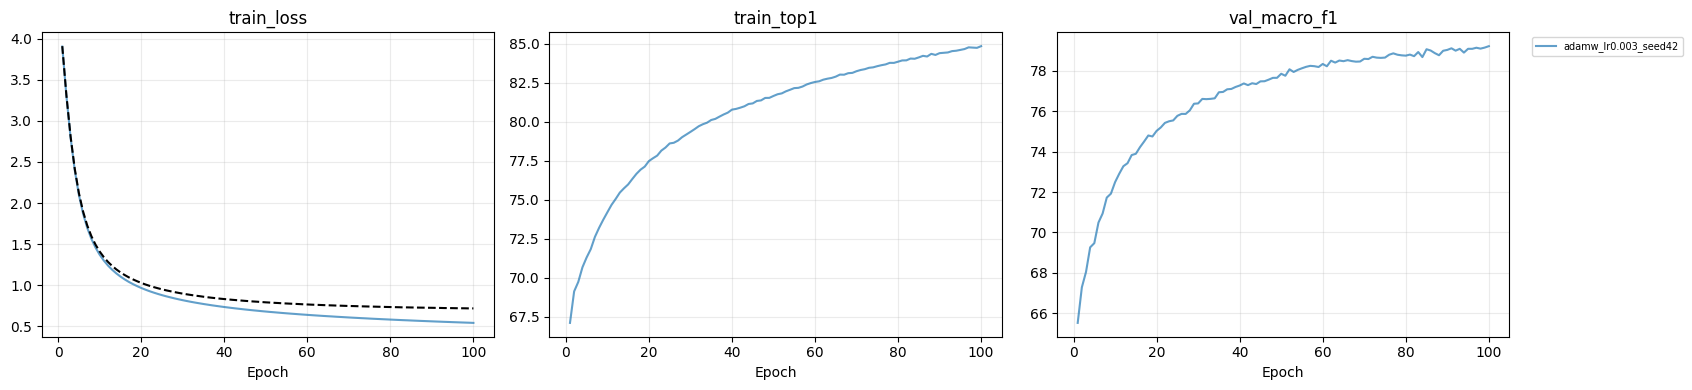

In [ ]:
import torch.nn as nn
from torch.utils.data import TensorDataset

def fit_torch_probe(X_train,y_train,X_val,y_val,seed,lr,epochs=EPOCHS,patience=PATIENCE):
    torch.manual_seed(seed);np.random.seed(seed);random.seed(seed)
    net=nn.Linear(X_train.shape[1],100).to(DEVICE)
    optim=torch.optim.AdamW(net.parameters(),lr=lr,weight_decay=1e-3)
    loss_fn=nn.CrossEntropyLoss()
    loader=DataLoader(TensorDataset(torch.from_numpy(X_train).float(),torch.from_numpy(y_train).long()),batch_size=512,shuffle=True)
    va_x=torch.from_numpy(X_val).float().to(DEVICE);va_y=torch.from_numpy(y_val).long().to(DEVICE)
    tr_x=torch.from_numpy(X_train).float().to(DEVICE);tr_y=torch.from_numpy(y_train).long().to(DEVICE)
    hist=[];best_state=None;best_score=(-1,float('-inf'));bad=0
    for epoch in range(1,epochs+1):
        net.train()
        for xb,yb in loader:
            xb=xb.to(DEVICE);yb=yb.to(DEVICE)
            optim.zero_grad();loss=loss_fn(net(xb),yb)
            assert torch.isfinite(loss),'Nonfinite training loss'
            loss.backward();optim.step()
        net.eval()
        with torch.inference_mode():
            # full-batch inference chunked to avoid GPU OOM
            def logits_all(x):return torch.cat([net(x[i:i+4096]) for i in range(0,len(x),4096)]).cpu().numpy()
            tr_logits=logits_all(tr_x);va_logits=logits_all(va_x)
            train_loss=loss_fn(torch.from_numpy(tr_logits),torch.from_numpy(y_train)).item()
            val_loss=loss_fn(torch.from_numpy(va_logits),torch.from_numpy(y_val)).item()
        mt=metrics(y_train,tr_logits);mv=metrics(y_val,va_logits)
        hist.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
                     'train_top1':mt['top1'],'val_top1':mv['top1'],'val_top5':mv['top5'],'val_macro_f1':mv['macro_f1']})
        score=(mv['macro_f1'],-val_loss)
        if score>best_score:
            best_score=score;best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()};best_epoch=epoch;bad=0
        else:bad+=1
        if bad>=patience:break
    net.load_state_dict(best_state)
    return net,pd.DataFrame(hist),best_epoch

def torch_logits(net,X):
    net.eval();parts=[]
    with torch.inference_mode():
        for start in range(0,len(X),4096):parts.append(net(torch.from_numpy(X[start:start+4096]).float().to(DEVICE)).cpu().numpy())
    return np.concatenate(parts)

probe_runs=[];best_probe=None;best_probe_score=(-1,float('-inf'))
for lr in LR_GRID:
    for seed in SEEDS:
        name=f'adamw_lr{lr}_seed{seed}'
        t_train=time.perf_counter()
        net,h,bep=fit_torch_probe(Xtr,ytr,Xva,yva,seed,lr)
        fit_seconds=round(time.perf_counter()-t_train,2)
        h['method']=name;h['seed']=seed;h['lr']=lr
        h.to_csv(OUT/'tables'/f'curve_{name}.csv',index=False)
        val_logits=torch_logits(net,Xva)
        r=record(name,'val',yva,val_logits,val_idx,{'seed':seed,'lr':lr,'best_epoch':bep,'fit_seconds':fit_seconds})
        probe_runs.append(r)
        score=(r['macro_f1'],-float(h.loc[h.epoch==bep,'val_loss'].iloc[0]))
        if score>best_probe_score:best_probe_score=score;best_probe=(name,net,h,bep,lr,seed)
    print('Finished lr',lr)
name,net,h,bep,chosen_lr,chosen_seed=best_probe
print('Selected on validation:',name,'epoch',bep)
torch.save({'state_dict':net.state_dict(),'epoch':bep,'lr':chosen_lr,'seed':chosen_seed},OUT/'models'/'adamw_best_val.pt')


fig,axs=plt.subplots(1,3,figsize=(17,4))
for col,ax in zip(['train_loss','train_top1','val_macro_f1'],axs):
    for rr in probe_runs:
        hh=pd.read_csv(OUT/'tables'/f"curve_{rr['method']}.csv")
        ax.plot(hh.epoch,hh[col],label=rr['method'],alpha=.7)
    if col=='train_loss':
        hh=pd.read_csv(OUT/'tables'/f'curve_{name}.csv');ax.plot(hh.epoch,hh.val_loss,'k--',label='selected val loss')
    ax.set_title(col);ax.set_xlabel('Epoch');ax.grid(alpha=.25)
axs[-1].legend(fontsize=7,bbox_to_anchor=(1.04,1),loc='upper left')
plt.tight_layout();plt.savefig(OUT/'figures'/'training_curves.png',dpi=180,bbox_inches='tight');plt.show()

## 7. Ablation: kích thước train và số lượng prompt
Đánh giá validation khi tăng số lượng mẫu mỗi lớp (stratified). Không dùng test để chọn cấu hình. Kết quả ghi ra CSV và hình. Với prompt ablation, ensemble sử dụng prefix cố định của danh sách 18 mẫu.

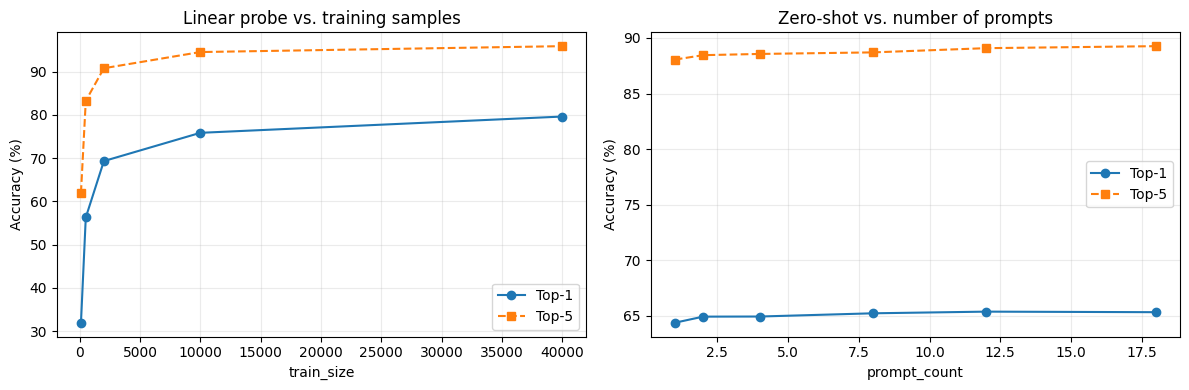

In [ ]:

ablation = []

if RUN_ABLATIONS:
    rng = np.random.default_rng(SEED)

    # Thí nghiệm 1: Ảnh hưởng của số lượng ảnh huấn luyện
    for sz in TRAIN_SIZES:
        if sz > len(Xtr):
            continue

        if sz == len(Xtr):
            # Sử dụng toàn bộ 40.000 ảnh Train
            inds = np.arange(len(ytr))
        else:
            # Lấy mẫu phân tầng để giữ tỷ lệ các lớp
            inds, _ = train_test_split(
                np.arange(len(ytr)),
                train_size=sz,
                stratify=ytr,
                random_state=SEED
            )

        clf = LogisticRegression(
            C=best_C,
            max_iter=1000
        )
        clf.fit(Xtr[inds], ytr[inds])

        scores = clf.predict_proba(Xva)

        ablation.append({
            'ablation': 'train_size',
            'value': sz,
            **metrics(yva, scores)
        })

    # Thí nghiệm 2: Ảnh hưởng của số lượng prompt
    for k in [1, 2, 4, 8, 12, 18]:
        w = text_weights(PROMPTS['ensemble_18'][:k])
        scores = Xva @ w.T

        ablation.append({
            'ablation': 'prompt_count',
            'value': k,
            **metrics(yva, scores)
        })

    # Lưu bảng kết quả Validation
    df_ab = pd.DataFrame(ablation)
    df_ab.to_csv(
        OUT / 'tables' / 'ablations_validation.csv',
        index=False
    )

    # Vẽ biểu đồ
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    experiments = [
        ('train_size', 'Linear probe vs. training samples'),
        ('prompt_count', 'Zero-shot vs. number of prompts')
    ]

    for ax, (kind, title) in zip(axs, experiments):
        sub = df_ab[df_ab.ablation == kind]

        ax.plot(sub.value, sub.top1, 'o-', label='Top-1')
        ax.plot(sub.value, sub.top5, 's--', label='Top-5')

        ax.set_title(title)
        ax.set_xlabel(kind)
        ax.set_ylabel('Accuracy (%)')
        ax.legend()
        ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        OUT / 'figures' / 'ablations.png',
        dpi=180
    )
    plt.show()

else:
    print('Ablations disabled')


### Superclass và nhóm A/B/C
20 superclass là nhóm có sẵn của CIFAR-100. Không gọi đây là nhóm câu hỏi A/B/C. Trong phần bổ sung Test cuối notebook, nhóm A/B/C sẽ được định nghĩa **chỉ bằng độ khó của từng lớp trên Validation**, rồi áp dụng cố định lên Test.


## 8. Phân tích nhóm: 20 superclass, Top-1/Top-5, Macro-F1
Mỗi fine class thuộc đúng một superclass. Nhóm được tính theo nhãn thật. Thống kê riêng validation và test, so sánh zero-shot với linear probe; **không gọi đây là nhóm câu hỏi**.

**Định nghĩa:** `within_group_fine_macro_f1` là F1 fine-class tính trên các ảnh có nhãn thật thuộc nhóm; không phải F1 superclass trên toàn bộ dataset. `superclass_top1` là tỷ lệ dự đoán thuộc đúng nhóm lớn, dù sai lớp con.


split                    method  group_id               group_name   n  correct_top1  correct_top5  top1  top5  within_group_fine_macro_f1  correct_superclass_top1  superclass_top1
  val          zero_ensemble_18         1                     fish 500           186           373  37.2  74.6                   42.774363                      325             65.0
  val          zero_ensemble_18         0          aquatic_mammals 500           212           386  42.4  77.2                   48.227236                      317             63.4
  val          zero_ensemble_18        15                 reptiles 500           221           390  44.2  78.0                   56.095739                      273             54.6
  val          zero_ensemble_18        12           medium_mammals 500           234           413  46.8  82.6                   58.512726                      284             56.8
  val          zero_ensemble_18        16            small_mammals 500           238           

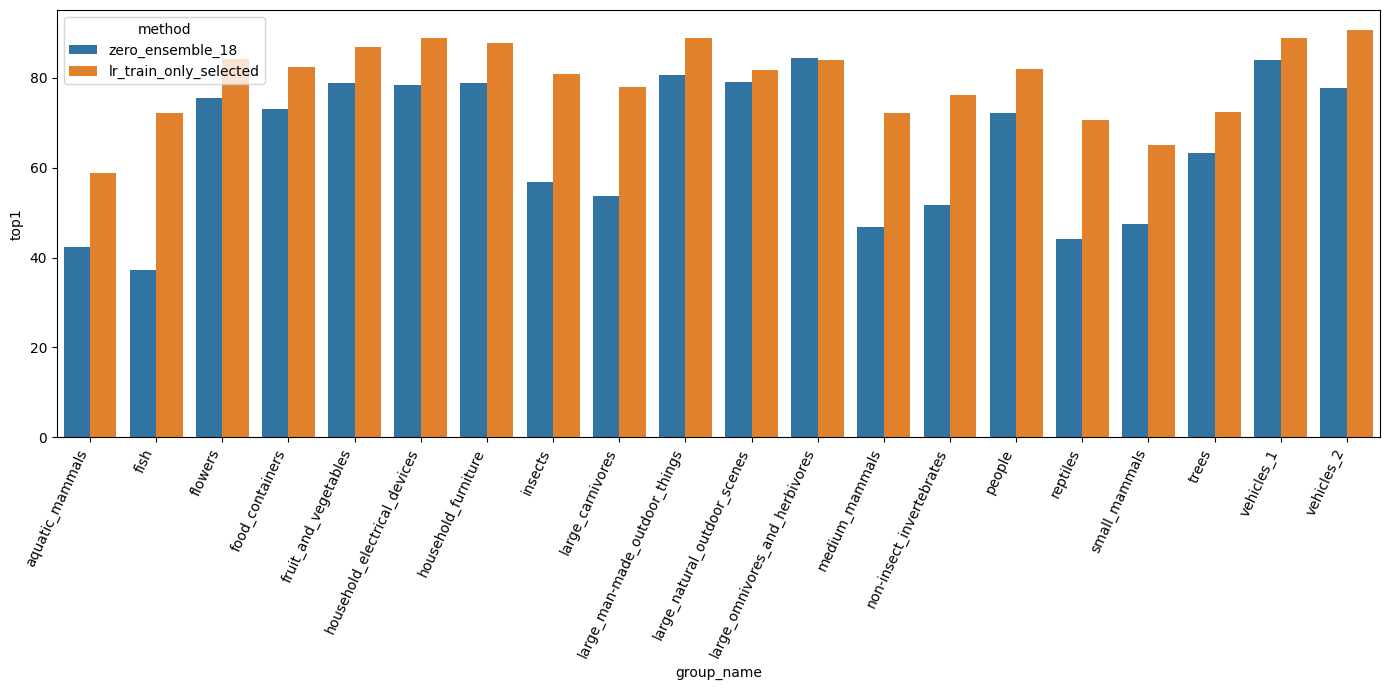

In [ ]:
# CIFAR-100 fine-label -> coarse-label mapping theo metadata gốc của torchvision pickle
import pickle
base=Path(ROOT)/'cifar-100-python'
with open(base/'train','rb') as f: meta_train=pickle.load(f,encoding='bytes')
with open(base/'test','rb') as f: meta_test=pickle.load(f,encoding='bytes')
with open(base/'meta','rb') as f: meta=pickle.load(f,encoding='bytes')
coarse_names=[s.decode() for s in meta[b'coarse_label_names']]
coarse_train=np.asarray(meta_train[b'coarse_labels'])
coarse_test=np.asarray(meta_test[b'coarse_labels'])
fine_to_coarse={}
for fine,coarse in zip(meta_train[b'fine_labels'],coarse_train):
    assert fine not in fine_to_coarse or fine_to_coarse[fine]==coarse
    fine_to_coarse[fine]=int(coarse)
assert len(fine_to_coarse)==100

def group_table(y,scores,split,method):
    coarse=np.array([fine_to_coarse[int(c)] for c in y]);pred=scores.argmax(1)
    top5=np.argsort(-scores,axis=1)[:,:5];rows=[]
    for g in range(20):
        mask=coarse==g
        rows.append({'split':split,'method':method,'group_id':g,'group_name':coarse_names[g],
                     'n':int(mask.sum()),'correct_top1':int((pred[mask]==y[mask]).sum()),
                     'correct_top5':int((top5[mask]==y[mask,None]).any(1).sum()),
                     'top1':100*np.mean(pred[mask]==y[mask]),
                     'top5':100*np.mean((top5[mask]==y[mask,None]).any(1)),
                     'within_group_fine_macro_f1':100*f1_score(y[mask],pred[mask],labels=sorted(set(y[mask])),average='macro',zero_division=0),
                     'correct_superclass_top1':int(np.sum(np.array([fine_to_coarse[int(p)] for p in pred[mask]])==g)),
                     'superclass_top1':100*np.mean(np.array([fine_to_coarse[int(p)] for p in pred[mask]])==g)})
    return pd.DataFrame(rows)

groups=[]
for split,y,X,zero in [('val',yva,Xva,zero_scores[best_prompt]['val'])]:
    groups.append(group_table(y,zero,split,'zero_'+best_prompt))
    groups.append(group_table(y,best_clf.predict_proba(X),split,'lr_train_only_selected'))
    groups.append(group_table(y,torch_logits(net,X),split,'adamw_selected_train_only'))

group_df=pd.concat(groups,ignore_index=True)
group_df.to_csv(OUT/'tables'/'group_metrics.csv',index=False)
print(group_df[group_df.split=='val'].sort_values('top1').head(15).to_string(index=False))
plotdf=group_df[(group_df.split=='val')&group_df.method.isin(['zero_'+best_prompt,'lr_train_only_selected'])]
plt.figure(figsize=(14,7));sns.barplot(data=plotdf,x='group_name',y='top1',hue='method')
plt.xticks(rotation=65,ha='right');plt.tight_layout();plt.savefig(OUT/'figures'/'superclass_top1.png',dpi=180);plt.show()

## 9. Ma trận nhầm lẫn của Logistic Regression, nhóm khó, ví dụ lỗi thật
Chọn trường hợp dự đoán sai trên Validation ở phần này; Test được phân tích riêng tại ô cuối, kèm nhãn thật và top-5 dự đoán; không diễn giải nguyên nhân bằng suy đoán như thể đã kiểm chứng. Đề xuất kiểm tra lỗi thị giác, tương đồng lớp, chất lượng ảnh, bias prompt dựa trên ví dụ cụ thể.

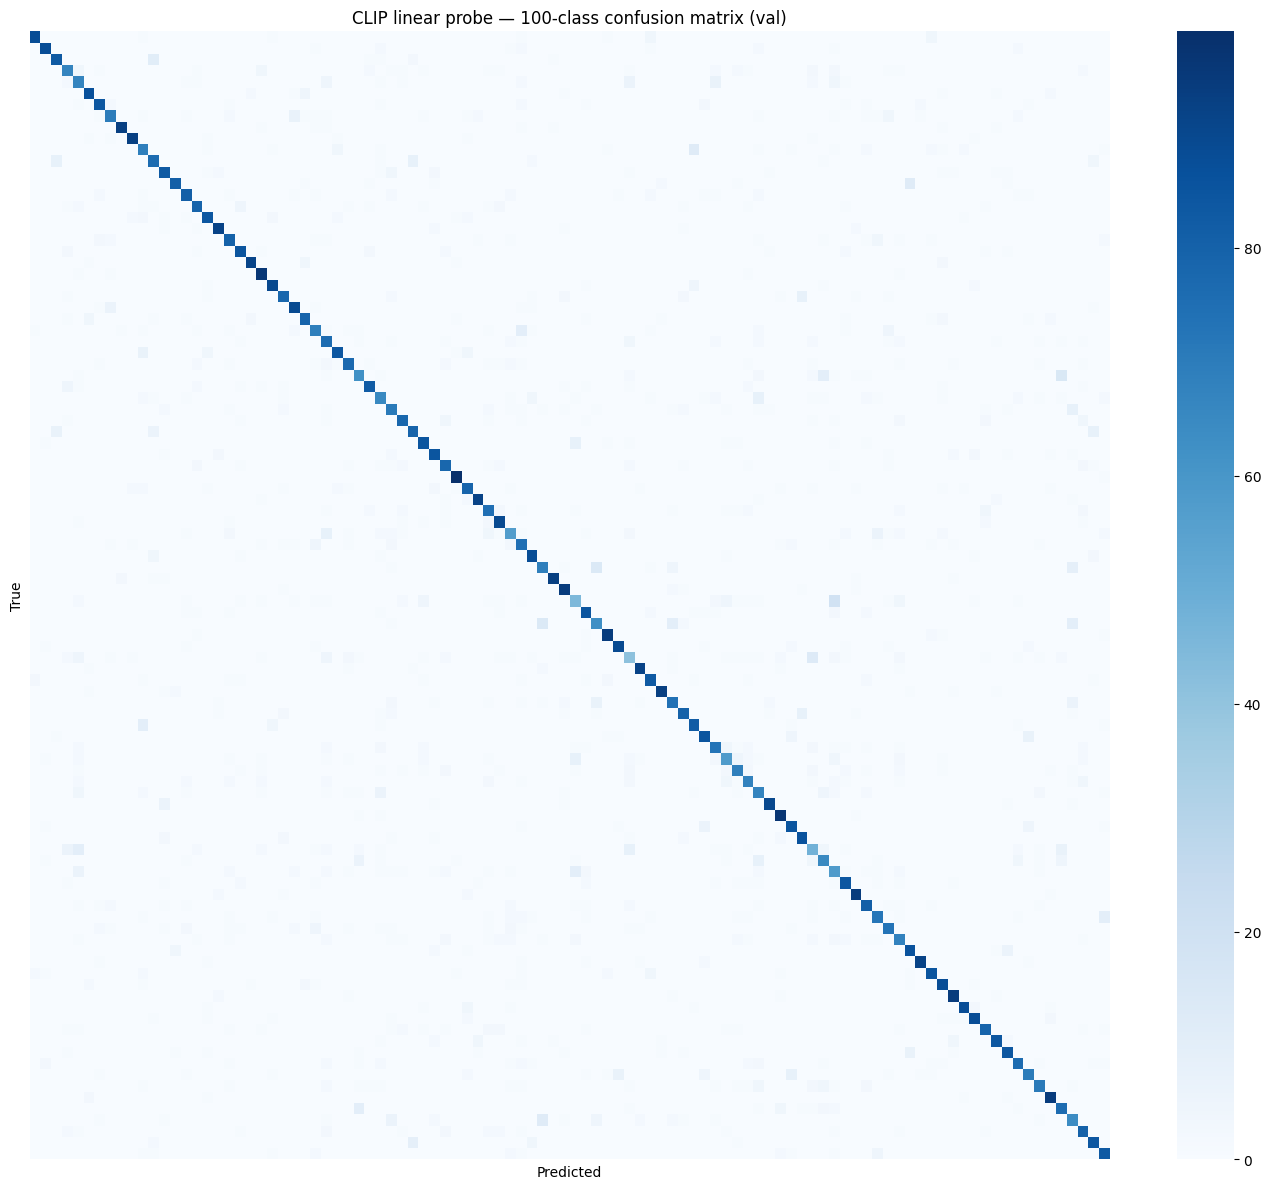

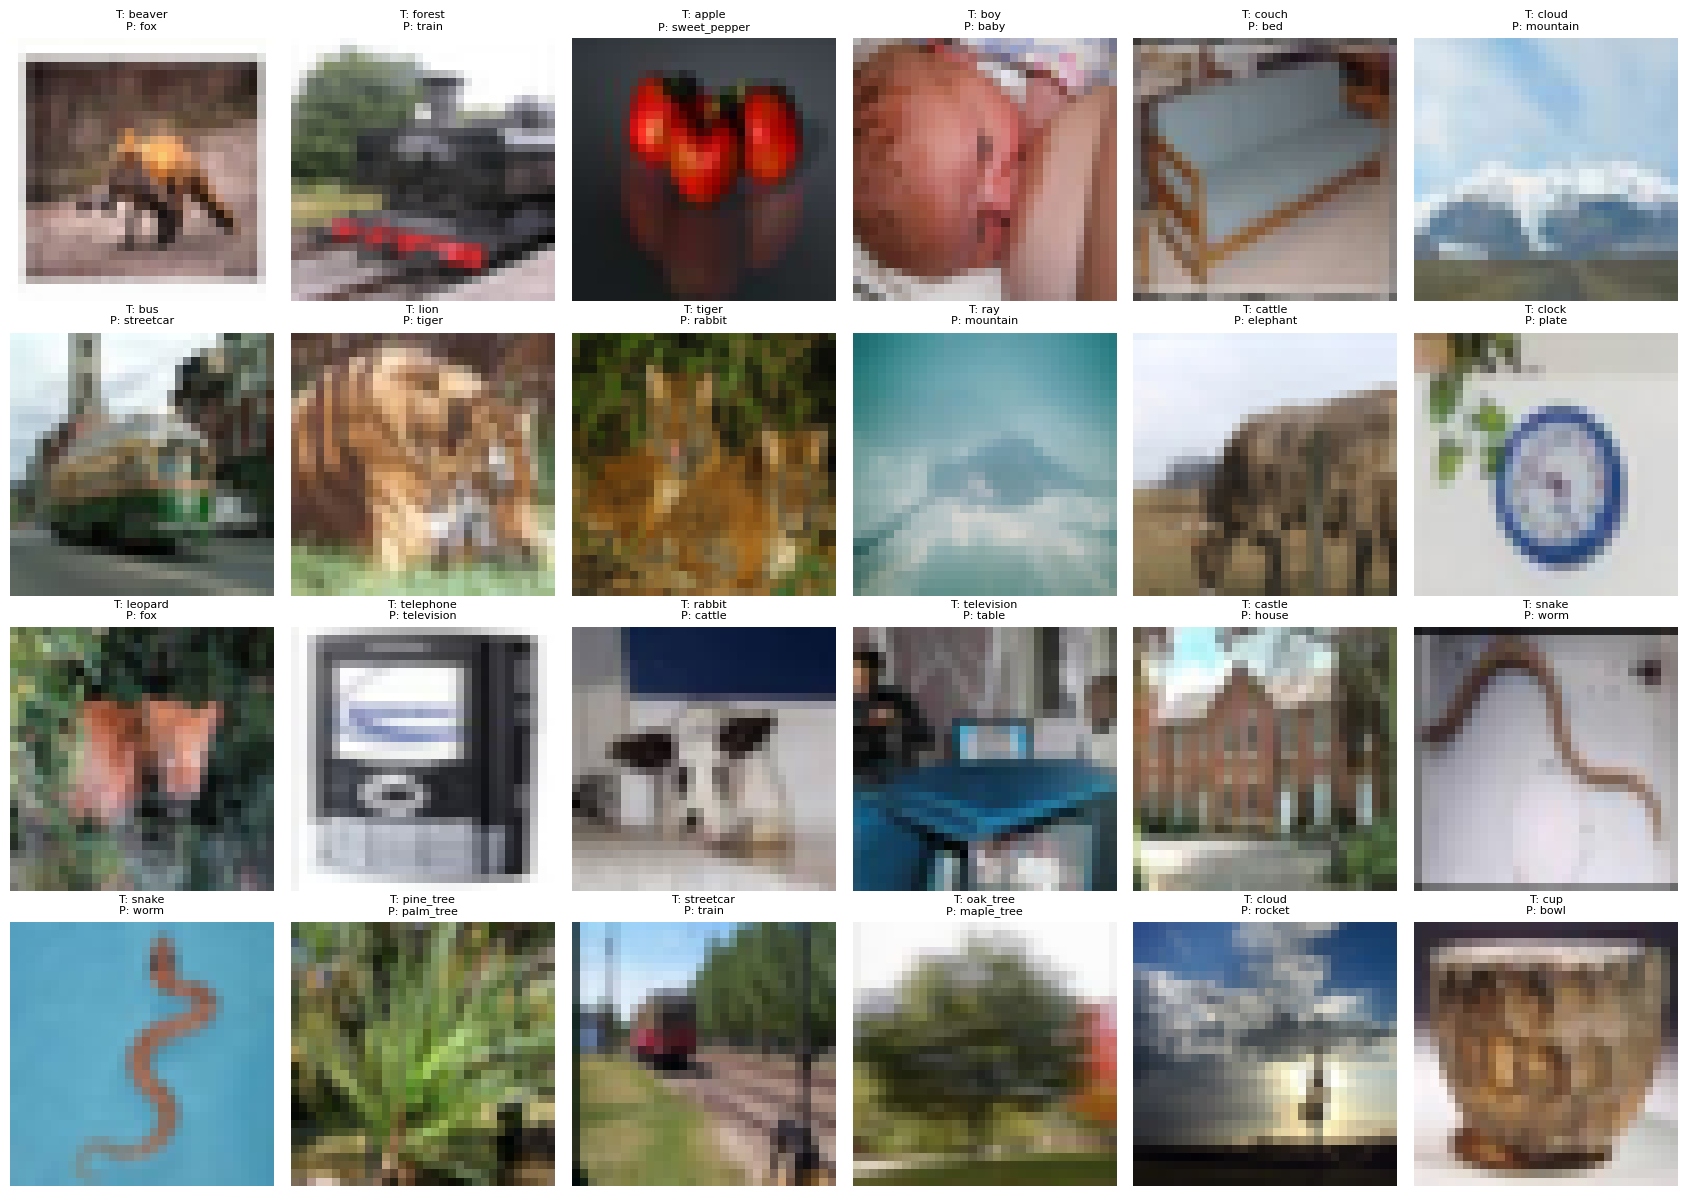

Saved 24 real error examples


In [ ]:
analysis_split='val'
Ay=yva
AX=Xva
Aidx=val_idx
Ascores=best_clf.predict_proba(Xva)
Apred=Ascores.argmax(1)
cm=confusion_matrix(Ay,Apred,labels=np.arange(100))
pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUT/'tables'/f'confusion_matrix_{analysis_split}.csv')
plt.figure(figsize=(14,12));sns.heatmap(cm,cmap='Blues',xticklabels=False,yticklabels=False)
plt.title('CLIP Logistic Regression linear probe — 100-class confusion matrix ('+analysis_split+')');plt.xlabel('Predicted');plt.ylabel('True')
plt.tight_layout();plt.savefig(OUT/'figures'/'confusion_matrix.png',dpi=180);plt.show()
err=np.flatnonzero(Apred!=Ay)
# Lấy lỗi có độ tin cậy cao để tìm failure mode (không chọn theo nhãn test để tune model)
confidence=Ascores.max(1)
err=err[np.argsort(-confidence[err])][:24]
rows=[]
for i in err:
    top=np.argsort(-Ascores[i])[:5]
    rows.append({'index':int(Aidx[i]),'true':classes[Ay[i]],'pred':classes[Apred[i]],
                 'confidence':float(confidence[i]),'top5':', '.join(classes[j] for j in top),
                 'superclass':coarse_names[fine_to_coarse[int(Ay[i])]]})
pd.DataFrame(rows).to_csv(OUT/'tables'/f'error_cases_{analysis_split}.csv',index=False)
fig,axs=plt.subplots(4,6,figsize=(17,12))
raw=raw_train
for ax,i in zip(axs.flat,err):
    im,_=raw[int(Aidx[i])]
    ax.imshow(im);ax.set_title(f'T: {classes[Ay[i]]}\nP: {classes[Apred[i]]}',fontsize=8);ax.axis('off')
for ax in list(axs.flat)[len(err):]:ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'figures'/'error_gallery.png',dpi=180);plt.show()
print('Saved',len(err),'real error examples')

## 11. Phân tích chi tiết 100 lớp, cặp nhầm lẫn và độ khó
Báo cáo mỗi lớp có bao nhiêu ảnh, bao nhiêu dự đoán Top-1 đúng và Top-5 đúng, Precision/Recall/F1; các cặp nhầm lẫn phổ biến; độ chênh lệch zero-shot và linear probe. Các con số là thống kê thực nghiệm; **nguyên nhân** cần được kiểm tra thêm bằng gallery ảnh, không suy luận trực tiếp từ tên lớp.

10 lowest recall classes (linear probe):
 class_name      superclass   n  top1_correct  top5_correct  recall
      otter aquatic_mammals 100            41            90    0.41
      mouse   small_mammals 100            45            91    0.45
       seal aquatic_mammals 100            48            88    0.48
     lizard        reptiles 100            57            85    0.57
     possum  medium_mammals 100            58            91    0.58
      shrew   small_mammals 100            58            86    0.58
    dolphin aquatic_mammals 100            62            94    0.62
   oak_tree           trees 100            63           100    0.63
willow_tree           trees 100            64            93    0.64
   flatfish            fish 100            65            92    0.65
Top confusion pairs:
split       method  true_id  pred_id   true_name  pred_name  count
  val linear_probe       50       74       mouse      shrew     19
  val linear_probe       30       95     dolphin      wh

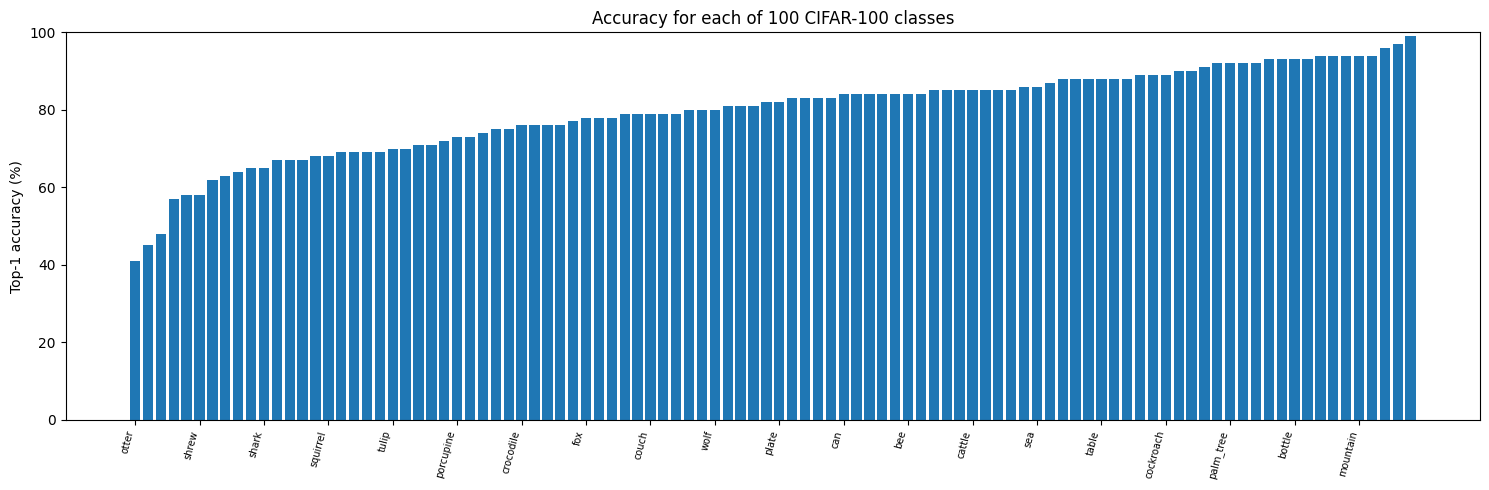

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
fine_rows=[];pair_rows=[]
for split,y,idx,zscore,lscores in [('val',yva,val_idx,zero_scores[best_prompt]['val'],best_clf.predict_proba(Xva))]:
    for method,scores in [('zero_'+best_prompt,zscore),('linear_probe',lscores)]:
        pred=scores.argmax(1);top5=np.argsort(-scores,axis=1)[:,:5]
        pp,rr,ff,_=precision_recall_fscore_support(y,pred,labels=np.arange(100),zero_division=0)
        for c in range(100):
            mask=y==c
            fine_rows.append({'split':split,'method':method,'class_id':c,'class_name':classes[c],
             'superclass':coarse_names[fine_to_coarse[c]],'n':int(mask.sum()),
             'top1_correct':int((pred[mask]==c).sum()),'top5_correct':int((top5[mask]==c).any(1).sum()),
             'top1_pct':100*np.mean(pred[mask]==c),'top5_pct':100*np.mean((top5[mask]==c).any(1)),
             'precision':pp[c],'recall':rr[c],'f1':ff[c]})
        pairs=pd.DataFrame({'true':y,'pred':pred}).query('true != pred').groupby(['true','pred']).size().sort_values(ascending=False).head(40)
        for (a,b),count in pairs.items():
            pair_rows.append({'split':split,'method':method,'true_id':int(a),'pred_id':int(b),
              'true_name':classes[a],'pred_name':classes[b],'count':int(count)})
fine_df=pd.DataFrame(fine_rows);fine_df.to_csv(OUT/'tables'/'per_class_metrics.csv',index=False)
pd.DataFrame(pair_rows).to_csv(OUT/'tables'/'top_confusion_pairs.csv',index=False)
show_split='val'
print('10 lowest recall classes (linear probe):')
print(fine_df.query('split == @show_split and method == "linear_probe"').nsmallest(10,'recall')[['class_name','superclass','n','top1_correct','top5_correct','recall']].to_string(index=False))
print('Top confusion pairs:')
print(pd.DataFrame(pair_rows).query('split == @show_split and method == "linear_probe"').head(15).to_string(index=False))
plt.figure(figsize=(15,5))
sub=fine_df.query('split == @show_split and method == "linear_probe"').sort_values('top1_pct')
plt.bar(np.arange(100),sub.top1_pct);plt.xticks(np.arange(0,100,5),sub.class_name.iloc[::5],rotation=75,ha='right',fontsize=7)
plt.ylim(0,100);plt.ylabel('Top-1 accuracy (%)');plt.title('Accuracy for each of 100 CIFAR-100 classes')
plt.tight_layout();plt.savefig(OUT/'figures'/'per_class_accuracy.png',dpi=180);plt.show()

## 12. Độ ổn định và thống kê sai số
Dùng **paired bootstrap** trên cùng tập ảnh để ước lượng khoảng tin cậy 95% cho chênh lệch Top-1 của hai phương pháp; đồng thời lưu bootstrap CI cho Top-1 từng phương pháp. Đây là **độ bất định do lấy mẫu ảnh test/validation**, không thay thế độ biến thiên qua seed huấn luyện. Khi đã dùng test để báo cáo, không dùng kết quả để quay lại chọn mô hình.

In [ ]:
if RUN_STATISTICAL_ANALYSIS:
    def paired_bootstrap(y,score_a,score_b,nboot=1000,seed=2026):
        rng=np.random.default_rng(seed);a=(score_a.argmax(1)==y).astype(float);b=(score_b.argmax(1)==y).astype(float)
        diffs=[];acc_a=[];acc_b=[]
        for _ in range(nboot):
            ids=rng.integers(0,len(y),len(y));acc_a.append(100*a[ids].mean());acc_b.append(100*b[ids].mean());diffs.append(100*(b[ids]-a[ids]).mean())
        return {'n':len(y),'method_a_top1':100*a.mean(),'method_b_top1':100*b.mean(),
         'delta_b_minus_a_pp':100*(b-a).mean(),'a_ci_low':np.percentile(acc_a,2.5),'a_ci_high':np.percentile(acc_a,97.5),
         'b_ci_low':np.percentile(acc_b,2.5),'b_ci_high':np.percentile(acc_b,97.5),
         'delta_ci_low':np.percentile(diffs,2.5),'delta_ci_high':np.percentile(diffs,97.5)}
    stat_rows=[]
    for split,y,z,l in [('val',yva,zero_scores[best_prompt]['val'],best_clf.predict_proba(Xva))]:
        stat_rows.append({'split':split,'comparison':'linear_probe minus zero_shot',**paired_bootstrap(y,z,l)})
    stat_df=pd.DataFrame(stat_rows);stat_df.to_csv(OUT/'tables'/'paired_bootstrap_ci.csv',index=False)
    print(stat_df.to_string(index=False))
else:print('Statistical analysis skipped')

split                   comparison     n  method_a_top1  method_b_top1  delta_b_minus_a_pp  a_ci_low  a_ci_high  b_ci_low  b_ci_high  delta_ci_low  delta_ci_high
  val linear_probe minus zero_shot 10000          65.33          79.62               14.29   64.4095   66.25025     78.84   80.45025      13.46975          15.24


## 13. Phân tích hội tụ định lượng, độ ổn định seed, và kiểm toán kết quả
Không chỉ vẽ loss: xuất bảng cho từng run gồm epoch tốt nhất, epoch cuối, chênh lệch train/validation, cải thiện loss và số epoch thực chạy. Thống kê trung bình theo seed **cho cùng learning rate**; với cấu hình hiện tại chỉ có seed 42, độ lệch chuẩn mẫu không xác định (NaN) và không thể suy ra độ ổn định giữa các seed. Cảnh báo nếu validation loss tăng trong khi train loss giảm. Cảnh báo này là chỉ dấu cần kiểm tra, không tự động chứng minh overfitting.

              method  seed    lr  epochs_run  best_epoch_by_macro_f1  final_epoch  initial_train_loss  final_train_loss  initial_val_loss  final_val_loss  best_val_macro_f1  last_val_macro_f1  final_train_val_top1_gap_pp  train_loss_decreased  val_loss_increased
adamw_lr0.003_seed42    42 0.003         100                     100          100            3.903921          0.541425          3.908607        0.717656           79.22761           79.22761                       5.5275                  True               False
   lr  n_seeds  val_top1_mean  val_top1_std  val_macro_f1_mean  val_macro_f1_std
0.003        1          79.32           NaN           79.22761               NaN


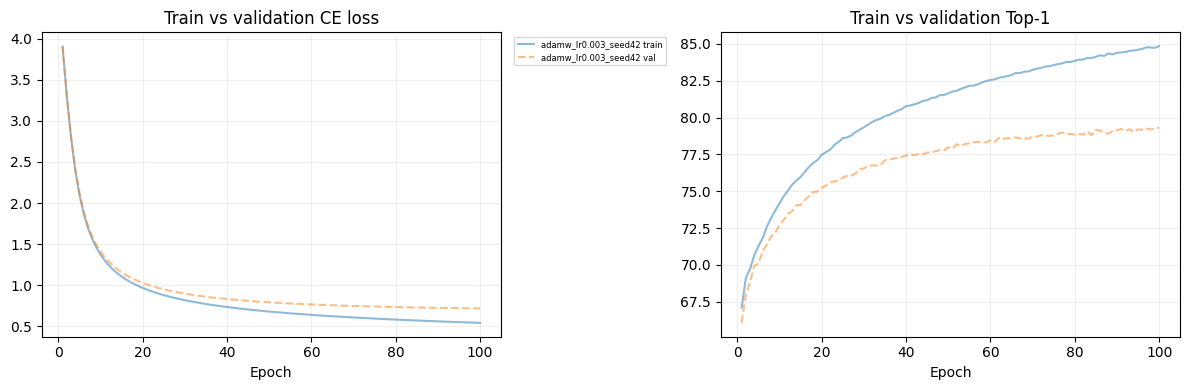

In [ ]:
convergence=[]
for rr in probe_runs:
    hh=pd.read_csv(OUT/'tables'/f"curve_{rr['method']}.csv")
    bestrow=hh.loc[hh.val_macro_f1.idxmax()];last=hh.iloc[-1]
    convergence.append({'method':rr['method'],'seed':rr['seed'],'lr':rr['lr'],'epochs_run':len(hh),
     'best_epoch_by_macro_f1':int(bestrow.epoch),'final_epoch':int(last.epoch),
     'initial_train_loss':hh.train_loss.iloc[0],'final_train_loss':last.train_loss,
     'initial_val_loss':hh.val_loss.iloc[0],'final_val_loss':last.val_loss,
     'best_val_macro_f1':hh.val_macro_f1.max(),'last_val_macro_f1':last.val_macro_f1,
     'final_train_val_top1_gap_pp':last.train_top1-last.val_top1,
     'train_loss_decreased':bool(last.train_loss<hh.train_loss.iloc[0]),
     'val_loss_increased':bool(last.val_loss>hh.val_loss.iloc[0])})
convergence_df=pd.DataFrame(convergence)
convergence_df.to_csv(OUT/'tables'/'convergence_diagnostics.csv',index=False)
seed_stability=pd.DataFrame(probe_runs).groupby('lr',as_index=False).agg(
 n_seeds=('seed','count'),val_top1_mean=('top1','mean'),val_top1_std=('top1','std'),
 val_macro_f1_mean=('macro_f1','mean'),val_macro_f1_std=('macro_f1','std'))
seed_stability.to_csv(OUT/'tables'/'seed_stability.csv',index=False)
print(convergence_df.to_string(index=False));print(seed_stability.to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for rr in probe_runs:
    hh=pd.read_csv(OUT/'tables'/f"curve_{rr['method']}.csv")
    axs[0].plot(hh.epoch,hh.train_loss,alpha=.5,label=rr['method']+' train')
    axs[0].plot(hh.epoch,hh.val_loss,linestyle='--',alpha=.5,label=rr['method']+' val')
    axs[1].plot(hh.epoch,hh.train_top1,alpha=.5)
    axs[1].plot(hh.epoch,hh.val_top1,linestyle='--',alpha=.5)
axs[0].set_title('Train vs validation CE loss');axs[1].set_title('Train vs validation Top-1')
for ax in axs:ax.set_xlabel('Epoch');ax.grid(alpha=.2)
axs[0].legend(fontsize=6,bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout();plt.savefig(OUT/'figures'/'convergence_train_val.png',dpi=180,bbox_inches='tight');plt.show()

## Kết quả chính thức của lần chạy hiện tại

**Không sử dụng bảng số liệu của các phiên Colab trước làm kết quả cho phiên này.** Bảng kết quả Test được tạo tự động ở ô cuối từ mô hình và embedding của chính lần chạy này. Không sử dụng các số liệu từ phiên chạy trước để thay thế kết quả tính tự động. Mọi số liệu phải lấy từ output Test của chính notebook này.

Phương pháp: Zero-shot CLIP (prompt chọn trên Validation); Logistic Regression (Train-only, C chọn trên Validation); AdamW linear probe (Train-only, checkpoint tốt nhất trên Validation).


## 14. Đánh giá Test và phân tích lỗi — chỉ thực hiện sau khi đã chốt Validation
Hai ô dưới đây mở tập Test **một lần** để đánh giá cả ba phương pháp, xuất bảng 20 superclass, 100 lớp, nhóm A/B/C, ma trận nhầm lẫn, ảnh lỗi, bảng thời gian và hội tụ. Các kiểm tra dùng số mẫu và phép đối chiếu nội bộ, **không ép số liệu phải trùng lần chạy trước**.


In [ ]:
# Chạy ô này sau khi chọn xong các mô hình trên Validation.
# Không huấn luyện lại, chỉ lấy Test embedding từ cache nếu đã có.
assert not RUN_TEST, 'Test đã được mở trước đó; kiểm tra quy trình trước khi tiếp tục.'
assert QUICK is False, 'Không dùng QUICK để đánh giá chính thức.'
RUN_TEST = True
Xte, yte = extract_cached(test_ds, test_idx, 'test')
assert Xte.shape == (10000, 512) and len(yte) == 10000
print('Đã sẵn sàng Test:', Xte.shape, yte.shape)


CLIP encode test:   0%|          | 0/40 [00:00<?, ?it/s]

Đã sẵn sàng Test: (10000, 512) (10000,)


KẾT QUẢ TEST CỦA LẦN CHẠY NÀY:
             method split     n  top1  top5  macro_f1
     Zero-shot CLIP  test 10000 65.12 89.24     64.31
Logistic Regression  test 10000 79.39 96.16     79.43
 AdamW Linear Probe  test 10000 78.84 96.04     78.86
THỜI GIAN (không gồm trích xuất embedding CLIP):
             method  classifier_fit_seconds  test_prediction_seconds
     Zero-shot CLIP                    0.00                    1.318
Logistic Regression                   81.07                    0.050
 AdamW Linear Probe                   56.55                    0.008

NHÓM ĐỘ KHÓ A/B/C (định nghĩa trên Validation):
             method          group    n  top1_correct  top5_correct  top1_pct  top5_pct
     Zero-shot CLIP         A (dễ) 3500          2985          3374     85.29     96.40
     Zero-shot CLIP B (trung bình) 3200          2148          2976     67.12     93.00
     Zero-shot CLIP        C (khó) 3300          1379          2574     41.79     78.00
Logistic Regression        

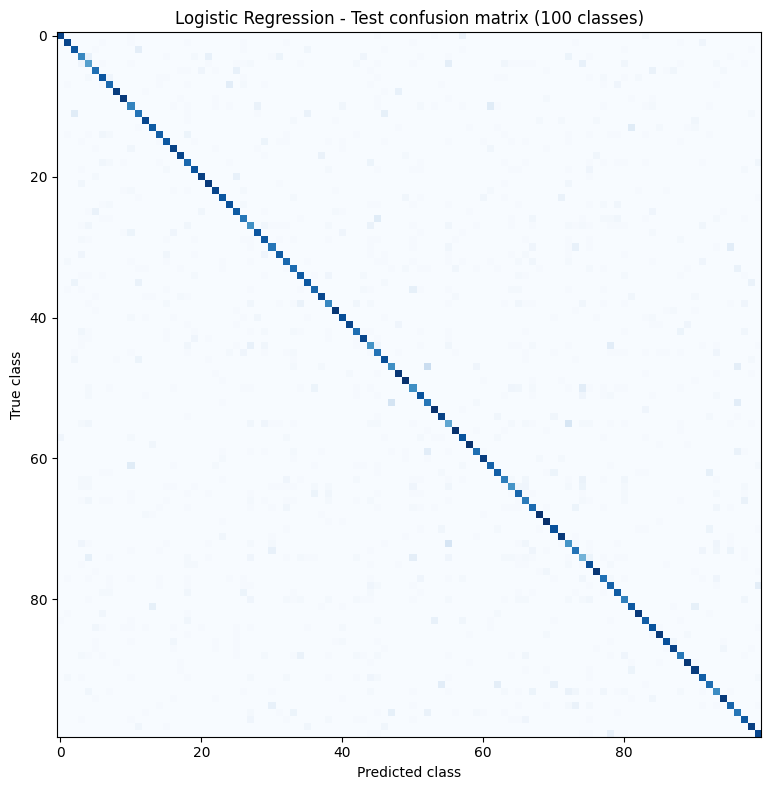

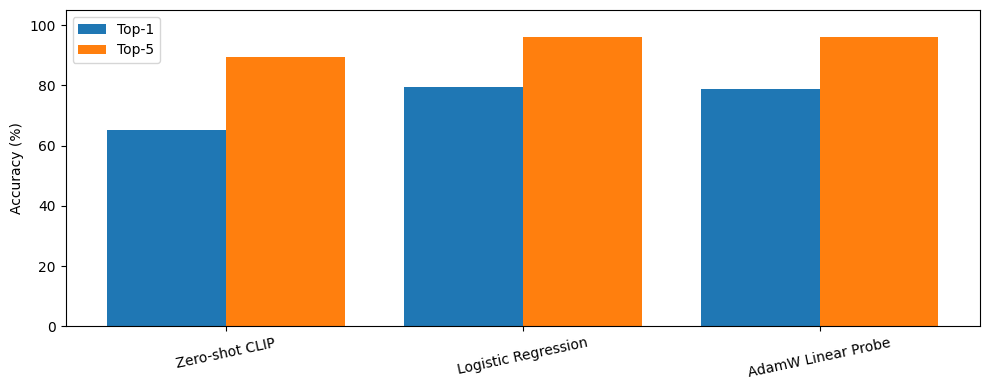

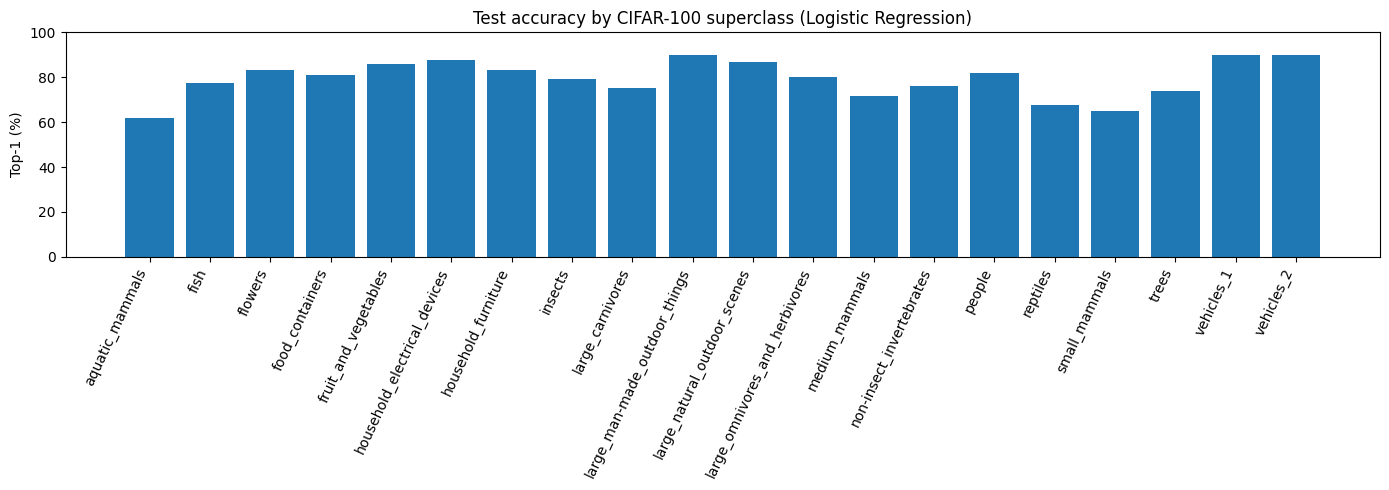

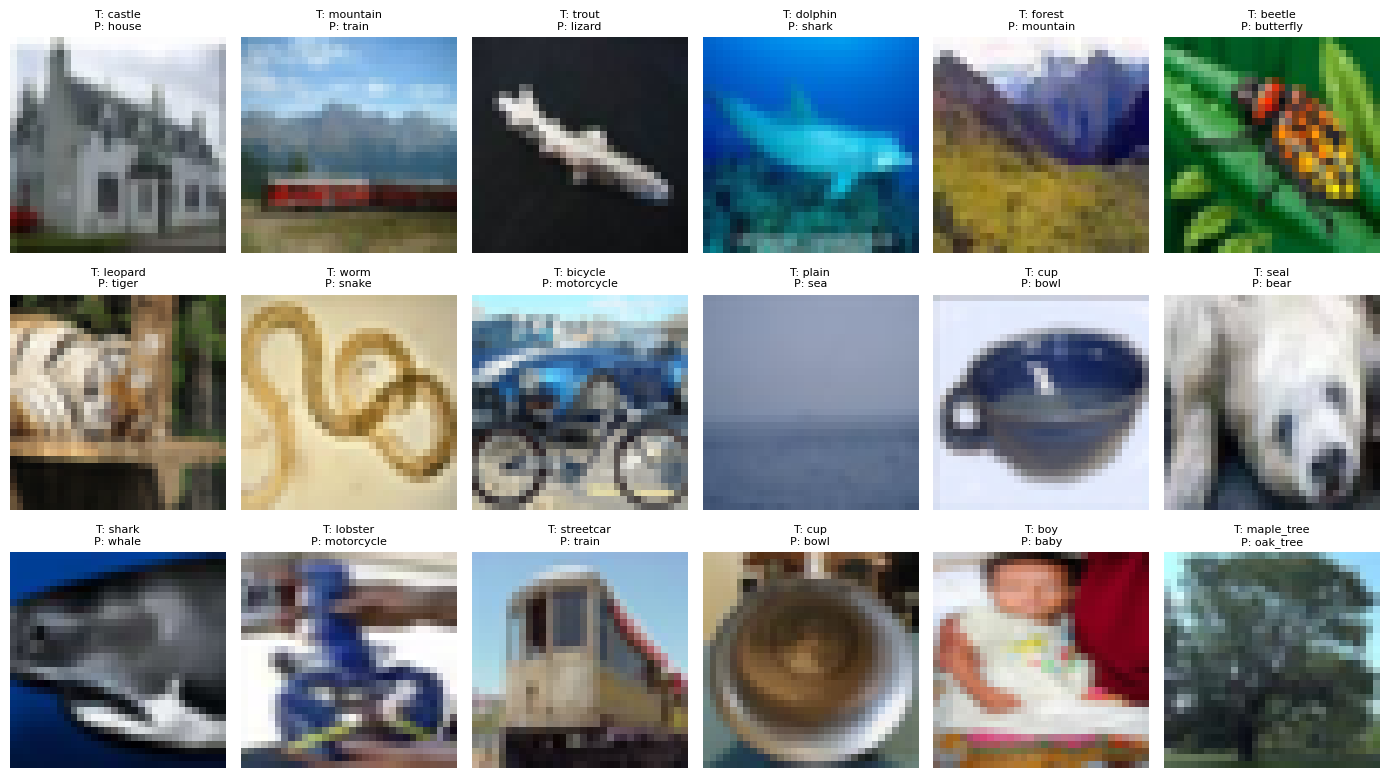

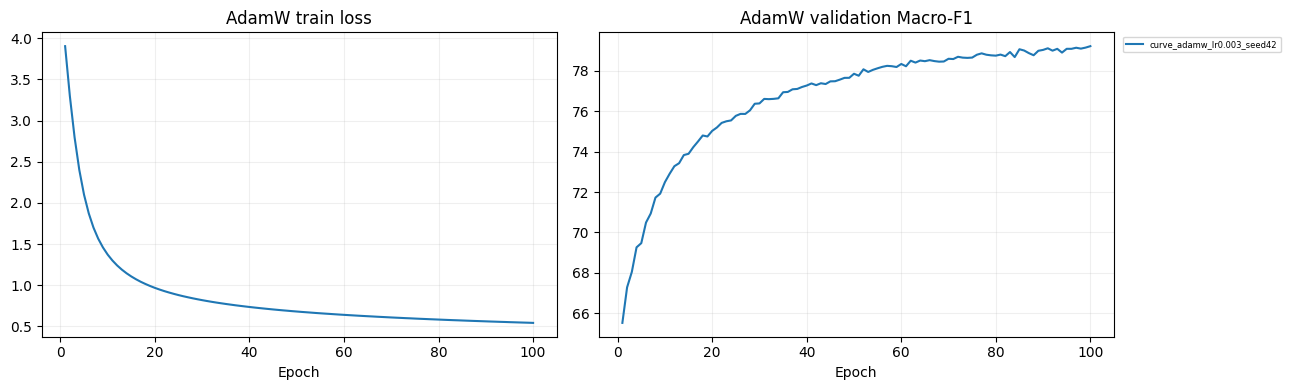


HỘI TỤ:
                       run  epochs  best_epoch  first_train_loss  last_train_loss  last_val_top1  best_epoch_is_last
curve_adamw_lr0.003_seed42     100         100          3.903921         0.541425          79.32                True
LƯU Ý: Epoch tốt nhất ở cuối; chưa đủ bằng chứng hội tụ.

HOÀN TẤT: các bảng và hình FULL đã được tạo và kiểm tra tại /content/drive/MyDrive/CLIP_Final_Experiments/FULL_EXPERIMENT_FINAL


In [ ]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import pickle, json

assert QUICK is False, 'DỪNG: đang ở QUICK, không xuất kết quả chính thức.'
assert len(ytr)==40000 and len(yva)==10000, 'Train/Val không đúng FULL.'
assert Xte is not None and Xte.shape==(10000,512) and len(yte)==10000, 'Chưa có embedding Test FULL.'
for sub in ['tables','figures','predictions','logs']:(OUT/sub).mkdir(parents=True,exist_ok=True)

# Kiểm tra checkpoint lưu trên Drive trùng mô hình đang dùng
ckpt_path=OUT/'models'/'adamw_best_val.pt'
assert ckpt_path.exists(), 'Thiếu checkpoint AdamW; kiểm tra thư mục FULL_EXPERIMENT/models.'
ckpt=torch.load(ckpt_path,map_location='cpu',weights_only=False)
assert abs(float(ckpt['lr'])-float(chosen_lr))<1e-10 and int(ckpt['seed'])==int(chosen_seed) and int(ckpt['epoch'])==int(bep)
net.load_state_dict(ckpt['state_dict']);net.to(DEVICE);net.eval()

# Không dùng Test để chọn tham số: chỉ áp dụng lựa chọn Validation
import time
if DEVICE=='cuda': torch.cuda.synchronize()
t0=time.perf_counter()
zs_test=Xte @ text_weights(PROMPTS[best_prompt]).T
if DEVICE=='cuda': torch.cuda.synchronize()
zs_seconds=time.perf_counter()-t0
t0=time.perf_counter()
lr_test=best_clf.predict_proba(Xte)
lr_seconds=time.perf_counter()-t0
if DEVICE=='cuda': torch.cuda.synchronize()
t0=time.perf_counter()
adamw_test=torch_logits(net,Xte)
if DEVICE=='cuda': torch.cuda.synchronize()
adamw_seconds=time.perf_counter()-t0
assert all(np.isfinite(s).all() and s.shape==(10000,100) for s in [zs_test,lr_test,adamw_test])

scores={'Zero-shot CLIP':zs_test,'Logistic Regression':lr_test,'AdamW Linear Probe':adamw_test}

def summary_row(method, s):
    pred=s.argmax(1); top5=np.argsort(-s,axis=1)[:,:5]
    return {'method':method,'split':'test','n':len(yte),
            'top1':round(100*np.mean(pred==yte),2),
            'top5':round(100*np.mean((top5==yte[:,None]).any(1)),2),
            'macro_f1':round(100*f1_score(yte,pred,average='macro',zero_division=0),2)}
summary=pd.DataFrame([summary_row(k,v) for k,v in scores.items()])
# Kiểm tra tính nhất quán bằng cách tính lại metrics từ scores, không dùng số cũ.
assert len(summary)==3 and (summary.n==10000).all()
assert summary[['top1','top5','macro_f1']].notna().all().all()
assert (summary.top5>=summary.top1).all()
summary.to_csv(OUT/'tables'/'three_methods_test_verified.csv',index=False)
print('KẾT QUẢ TEST CỦA LẦN CHẠY NÀY:');print(summary.to_string(index=False))
fit_lr=pd.DataFrame(lr_search)
fit_lr=fit_lr.loc[fit_lr.C==best_C,'fit_seconds'].iloc[0]
fit_adamw=pd.DataFrame(probe_runs).loc[lambda x:(x.lr==chosen_lr)&(x.seed==chosen_seed),'fit_seconds'].iloc[0]
time_df=pd.DataFrame([
 {'method':'Zero-shot CLIP','classifier_fit_seconds':0.0,'test_prediction_seconds':round(zs_seconds,3)},
 {'method':'Logistic Regression','classifier_fit_seconds':round(float(fit_lr),2),'test_prediction_seconds':round(lr_seconds,3)},
 {'method':'AdamW Linear Probe','classifier_fit_seconds':round(float(fit_adamw),2),'test_prediction_seconds':round(adamw_seconds,3)}])
time_df.to_csv(OUT/'tables'/'time_comparison.csv',index=False)
print('THỜI GIAN (không gồm trích xuất embedding CLIP):');print(time_df.to_string(index=False))

# Bảng superclass chính xác theo metadata CIFAR-100
base=Path(ROOT)/'cifar-100-python'
with open(base/'train','rb') as f: raw=pickle.load(f,encoding='bytes')
with open(base/'meta','rb') as f: meta=pickle.load(f,encoding='bytes')
coarse_names=[x.decode() for x in meta[b'coarse_label_names']]
fine_to_coarse={}
for f,c in zip(raw[b'fine_labels'],raw[b'coarse_labels']):
    assert f not in fine_to_coarse or fine_to_coarse[f]==c
    fine_to_coarse[f]=int(c)
assert len(fine_to_coarse)==100

# Định nghĩa nhóm A/B/C chỉ trên Validation của zero-shot
zs_val=zero_scores[best_prompt]['val']
val_pred=zs_val.argmax(1)
val_class_acc=np.array([np.mean(val_pred[yva==c]==c) for c in range(100)])
# Phân vị 1/3 và 2/3 của 100 độ chính xác lớp (tie được phân loại theo ngưỡng cố định)
q1,q2=np.quantile(val_class_acc,[1/3,2/3])
def difficulty(c):
    v=val_class_acc[int(c)]
    return 'A (dễ)' if v>=q2 else ('B (trung bình)' if v>=q1 else 'C (khó)')

rows=[];class_rows=[];diff_rows=[]
for method,s in scores.items():
    pred=s.argmax(1);top5=np.argsort(-s,axis=1)[:,:5]
    hit1=pred==yte;hit5=(top5==yte[:,None]).any(1)
    for g in range(20):
        mask=np.array([fine_to_coarse[int(c)]==g for c in yte])
        n=int(mask.sum());assert n==500
        rows.append({'method':method,'group_id':g,'superclass':coarse_names[g],
                     'n':n,'top1_correct':int(hit1[mask].sum()),'top5_correct':int(hit5[mask].sum()),
                     'top1_pct':round(100*hit1[mask].mean(),2),'top5_pct':round(100*hit5[mask].mean(),2)})
    for c in range(100):
        mask=yte==c;assert int(mask.sum())==100
        class_rows.append({'method':method,'class_id':c,'class_name':classes[c],
                           'superclass':coarse_names[fine_to_coarse[c]],'difficulty':difficulty(c),
                           'n':100,'top1_correct':int(hit1[mask].sum()),'top5_correct':int(hit5[mask].sum()),
                           'top1_pct':round(100*hit1[mask].mean(),2),'top5_pct':round(100*hit5[mask].mean(),2)})
    dlabels=np.array([difficulty(c) for c in yte])
    for group in ['A (dễ)','B (trung bình)','C (khó)']:
        mask=dlabels==group;n=int(mask.sum())
        diff_rows.append({'method':method,'group':group,'n':n,
                          'top1_correct':int(hit1[mask].sum()),'top5_correct':int(hit5[mask].sum()),
                          'top1_pct':round(100*hit1[mask].mean(),2),'top5_pct':round(100*hit5[mask].mean(),2)})
    pd.DataFrame({'test_index':test_idx,'true_id':yte,'pred_id':pred,
                  'top1_correct':hit1.astype(int),'top5_correct':hit5.astype(int)}).to_csv(
                  OUT/'predictions'/f'{method.lower().replace(" ","_")}_test.csv',index=False)

group_df=pd.DataFrame(rows);class_df=pd.DataFrame(class_rows);diff_df=pd.DataFrame(diff_rows)
group_df.to_csv(OUT/'tables'/'superclass_test_full.csv',index=False)
class_df.to_csv(OUT/'tables'/'per_class_test_full.csv',index=False)
diff_df.to_csv(OUT/'tables'/'difficulty_abc_test_full.csv',index=False)
assert len(group_df)==60 and len(class_df)==300 and len(diff_df)==9
for method in scores:
    part=group_df[group_df.method==method];srow=summary[summary.method==method].iloc[0]
    assert part.n.sum()==10000
    assert abs(100*part.top1_correct.sum()/10000-srow.top1)<.015
    assert abs(100*part.top5_correct.sum()/10000-srow.top5)<.015
    assert diff_df[diff_df.method==method].n.sum()==10000
print('\nNHÓM ĐỘ KHÓ A/B/C (định nghĩa trên Validation):')
print(diff_df.to_string(index=False))
print('\n20 SUPERCLASS — Logistic Regression:')
print(group_df[group_df.method=='Logistic Regression'].to_string(index=False))

# Ma trận nhầm lẫn Test và ảnh sai của Logistic Regression
lr_pred=lr_test.argmax(1)
cm=confusion_matrix(yte,lr_pred,labels=np.arange(100))
pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUT/'tables'/'confusion_matrix_test.csv')
fig,ax=plt.subplots(figsize=(10,8));ax.imshow(cm,cmap='Blues');ax.set_title('Logistic Regression - Test confusion matrix (100 classes)')
ax.set_xlabel('Predicted class');ax.set_ylabel('True class');plt.tight_layout()
fig.savefig(OUT/'figures'/'confusion_matrix_test.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(10,4))
x=np.arange(3);ax.bar(x-.2,summary.top1,width=.4,label='Top-1');ax.bar(x+.2,summary.top5,width=.4,label='Top-5')
ax.set_xticks(x,summary.method,rotation=12);ax.set_ylim(0,105);ax.set_ylabel('Accuracy (%)');ax.legend();plt.tight_layout()
fig.savefig(OUT/'figures'/'three_methods_test.png',dpi=170);plt.show()

fig,ax=plt.subplots(figsize=(14,5))
part=group_df[group_df.method=='Logistic Regression']
ax.bar(part.superclass,part.top1_pct);ax.set_ylim(0,100);ax.set_ylabel('Top-1 (%)')
ax.set_title('Test accuracy by CIFAR-100 superclass (Logistic Regression)')
plt.xticks(rotation=65,ha='right');plt.tight_layout()
fig.savefig(OUT/'figures'/'superclass_test_top1.png',dpi=170);plt.show()

errors=np.flatnonzero(lr_pred!=yte)
errors=errors[np.argsort(-lr_test.max(1)[errors])][:18]
error_rows=[];fig,axes=plt.subplots(3,6,figsize=(14,8))
for ax,i in zip(axes.flat,errors):
    im,_=raw_test[int(test_idx[i])]
    ax.imshow(im);ax.set_title(f'T: {classes[yte[i]]}\nP: {classes[lr_pred[i]]}',fontsize=8);ax.axis('off')
    error_rows.append({'test_index':int(test_idx[i]),'true':classes[yte[i]],'pred':classes[lr_pred[i]],
                       'max_probability':float(lr_test[i].max())})
for ax in list(axes.flat)[len(errors):]:ax.axis('off')
plt.tight_layout();fig.savefig(OUT/'figures'/'error_gallery_test.png',dpi=170);plt.show()
pd.DataFrame(error_rows).to_csv(OUT/'tables'/'error_gallery_test.csv',index=False)

# Hội tụ: chỉ dùng file FULL của các run đã có, không chạy lại training
curves=[]
for p in sorted((OUT/'tables').glob('curve_adamw_lr*_seed*.csv')):
    h=pd.read_csv(p)
    assert len(h)>=2 and {'epoch','train_loss','val_loss','val_macro_f1','train_top1','val_top1'}<=set(h.columns)
    curves.append((p.stem,h))
assert len(curves)==len(LR_GRID)*len(SEEDS), f'Số đường cong không đúng số run của lần chạy này: {len(curves)}.'
conv=[]
fig,axs=plt.subplots(1,2,figsize=(13,4))
for name,h in curves:
    idx=h.val_macro_f1.idxmax();best_epoch=int(h.loc[idx,'epoch'])
    conv.append({'run':name,'epochs':len(h),'best_epoch':best_epoch,
                 'first_train_loss':float(h.train_loss.iloc[0]),'last_train_loss':float(h.train_loss.iloc[-1]),
                 'last_val_top1':float(h.val_top1.iloc[-1]),
                 'best_epoch_is_last':bool(best_epoch==int(h.epoch.iloc[-1]))})
    axs[0].plot(h.epoch,h.train_loss,label=name);axs[1].plot(h.epoch,h.val_macro_f1,label=name)
axs[0].set_title('AdamW train loss');axs[1].set_title('AdamW validation Macro-F1')
for ax in axs:ax.set_xlabel('Epoch');ax.grid(alpha=.2)
axs[1].legend(fontsize=6,bbox_to_anchor=(1.01,1),loc='upper left')
plt.tight_layout();fig.savefig(OUT/'figures'/'convergence_full.png',dpi=170,bbox_inches='tight');plt.show()
conv_df=pd.DataFrame(conv);conv_df.to_csv(OUT/'tables'/'convergence_full.csv',index=False)
print('\nHỘI TỤ:');print(conv_df.to_string(index=False))
if conv_df.best_epoch_is_last.all():print('LƯU Ý: Epoch tốt nhất ở cuối; chưa đủ bằng chứng hội tụ.')

(OUT/'logs'/'final_verified_protocol.json').write_text(json.dumps({
    'quick':False,'train':40000,'val':10000,'test':10000,
    'backbone':'CLIP ViT-B/32 pretrained frozen','best_prompt':best_prompt,
    'best_C':best_C,'adamw_lr':chosen_lr,'adamw_seed':chosen_seed,
    'adamw_epoch':int(bep),'test_selection':False,
    'test_metrics':summary.to_dict(orient='records'),
    'abc_definition':'Validation zero-shot per-class Top-1 quantile thresholds',
    'abc_thresholds':[float(q1),float(q2)]},ensure_ascii=False,indent=2))
print('\nHOÀN TẤT: các bảng và hình FULL đã được tạo và kiểm tra tại',OUT)
